In [1]:
import pandas as pd
import numpy as np
import os

BASE = r"C:\Users\Khant Htoo Kyaw\Documents\Yangon_Thesis"

# Load master dataset
df = pd.read_csv(os.path.join(BASE, "data", "tables", "master_grid_complete.csv"))
print(f"Loaded: {df.shape}")

# Define target and features with NEW column names
TARGET = 'LST'

FEATURES = [
    'NDVI', 'EVI', 'NDWI', 'NDBI', 'SAVI', 'BSI',
    'BCR', 'building_count', 'mean_footprint', 'footprint_std',
    'morph_class', 'bldg_height_mean',
    'road_dens', 'dist_green', 'dist_centre',
    'elevation', 'slope',
    'builtup_density', 'population',
]

# Keep only features that exist
FEATURES = [f for f in FEATURES if f in df.columns]
print(f"Features confirmed: {len(FEATURES)}")
print(f"Features: {FEATURES}")

Loaded: (72481, 24)
Features confirmed: 19
Features: ['NDVI', 'EVI', 'NDWI', 'NDBI', 'SAVI', 'BSI', 'BCR', 'building_count', 'mean_footprint', 'footprint_std', 'morph_class', 'bldg_height_mean', 'road_dens', 'dist_green', 'dist_centre', 'elevation', 'slope', 'builtup_density', 'population']


In [2]:
# Clean 2023 baseline
df_clean = df.dropna(subset=['LST']).copy()
for col in FEATURES:
    if col in df_clean.columns:
        df_clean[col] = df_clean[col].fillna(df_clean[col].median())

# Calculate mean feature values per morphology class
class_means = df_clean.groupby('morph_class')[FEATURES].mean()

print("Mean feature values by morphology class:")
print("=" * 60)
# Print only columns that exist in class_means
show_cols = [c for c in ['NDVI', 'NDBI', 'BSI', 'BCR'] 
             if c in class_means.columns]
print(class_means[show_cols].round(3))

# Save class means
import os
class_means_path = os.path.join(BASE, "outputs", "tables",
                                "class_mean_features_2023.csv")
os.makedirs(os.path.join(BASE, "outputs", "tables"), exist_ok=True)
class_means.to_csv(class_means_path)
print(f"\nClass means saved: {class_means_path}")
print(f"\ndf_clean rows: {len(df_clean):,}")
print(f"Features confirmed: {len(FEATURES)}")

Mean feature values by morphology class:
              NDVI   NDBI    BSI    BCR
morph_class                            
1            0.428  0.009  0.048  0.014
2            0.451 -0.007  0.020  0.171
3            0.387  0.045  0.054  0.337
4            0.309  0.107  0.096  0.583
5            0.315  0.096  0.093  0.722

Class means saved: C:\Users\Khant Htoo Kyaw\Documents\Yangon_Thesis\outputs\tables\class_mean_features_2023.csv

df_clean rows: 72,481
Features confirmed: 19


In [3]:
# LULC to morphology class mapping
LULC_TO_MORPH = {
    1: 1,   # Dense tree     → Open/Green
    2: 1,   # Mixed veg      → Open/Green
    3: 1,   # Water          → Open/Green
    4: 4,   # High built-up  → High density
    5: 2,   # Low built-up   → Low density
    6: 1,   # Bare soil      → Open
    7: 1,   # Agriculture    → Open/Green
}

# Updated with YOUR ACTUAL class means from Cell 2 output
LULC_SPECTRAL = {
    1: {'NDVI': 0.428, 'NDBI': 0.009, 'BSI': 0.048,
        'BCR': 0.014, 'building_count': 0},     # Open/Green
    2: {'NDVI': 0.451, 'NDBI': -0.007, 'BSI': 0.020,
        'BCR': 0.171, 'building_count': 2},     # Low density
    3: {'NDVI': 0.387, 'NDBI': 0.045, 'BSI': 0.054,
        'BCR': 0.337, 'building_count': 6},     # Medium density
    4: {'NDVI': 0.309, 'NDBI': 0.107, 'BSI': 0.096,
        'BCR': 0.583, 'building_count': 10},    # High density
    5: {'NDVI': 0.315, 'NDBI': 0.096, 'BSI': 0.093,
        'BCR': 0.722, 'building_count': 8},     # Industrial
}

print("LULC spectral signatures updated with real Yangon values!")
print()
for cls, vals in LULC_SPECTRAL.items():
    print(f"Class {cls}: NDVI={vals['NDVI']:.3f}  "
          f"NDBI={vals['NDBI']:.3f}  "
          f"BSI={vals['BSI']:.3f}  "
          f"BCR={vals['BCR']:.3f}")

LULC spectral signatures updated with real Yangon values!

Class 1: NDVI=0.428  NDBI=0.009  BSI=0.048  BCR=0.014
Class 2: NDVI=0.451  NDBI=-0.007  BSI=0.020  BCR=0.171
Class 3: NDVI=0.387  NDBI=0.045  BSI=0.054  BCR=0.337
Class 4: NDVI=0.309  NDBI=0.107  BSI=0.096  BCR=0.583
Class 5: NDVI=0.315  NDBI=0.096  BSI=0.093  BCR=0.722


In [4]:
import rasterio
import numpy as np

# Load 2031 predicted LULC from MOLUSCE
lulc_2031_path = os.path.join(BASE, "data", "rasters", "LULC_2031_projected.tif")
lulc_2023_path = os.path.join(BASE, "data", "rasters", "LULC_2023_aligned.tif")

with rasterio.open(lulc_2031_path) as src:
    lulc_2031 = src.read(1).astype(float)
    lulc_meta = src.meta

with rasterio.open(lulc_2023_path) as src:
    lulc_2023 = src.read(1).astype(float)

print(f"LULC 2031 shape: {lulc_2031.shape}")
print(f"LULC 2023 shape: {lulc_2023.shape}")

# Class distribution comparison
class_names = {1:'Dense tree', 2:'Mixed veg', 3:'Water',
               4:'High built', 5:'Low built', 6:'Bare soil', 7:'Agriculture'}

print("\nLULC 2023 distribution:")
for cls in sorted(np.unique(lulc_2023[lulc_2023 > 0]).astype(int)):
    count = (lulc_2023 == cls).sum()
    pct = count / (lulc_2023 > 0).sum() * 100
    print(f"  Class {cls} ({class_names.get(cls,'?')}): {count:,} pixels ({pct:.1f}%)")

print("\nLULC 2031 PREDICTED distribution:")
for cls in sorted(np.unique(lulc_2031[lulc_2031 > 0]).astype(int)):
    count = (lulc_2031 == cls).sum()
    pct = count / (lulc_2031 > 0).sum() * 100
    print(f"  Class {cls} ({class_names.get(cls,'?')}): {count:,} pixels ({pct:.1f}%)")

LULC 2031 shape: (1315, 1312)
LULC 2023 shape: (1315, 1312)

LULC 2023 distribution:
  Class 1 (Dense tree): 37,415 pixels (4.5%)
  Class 2 (Mixed veg): 169,389 pixels (20.4%)
  Class 3 (Water): 32,288 pixels (3.9%)
  Class 4 (High built): 208,422 pixels (25.0%)
  Class 5 (Low built): 218,050 pixels (26.2%)
  Class 6 (Bare soil): 166,540 pixels (20.0%)

LULC 2031 PREDICTED distribution:
  Class 1 (Dense tree): 25,187 pixels (3.0%)
  Class 2 (Mixed veg): 178,028 pixels (21.4%)
  Class 3 (Water): 31,673 pixels (3.8%)
  Class 4 (High built): 204,455 pixels (24.6%)
  Class 5 (Low built): 233,195 pixels (28.0%)
  Class 6 (Bare soil): 159,745 pixels (19.2%)


In [5]:
import rasterio
import numpy as np
import geopandas as gpd

print("Building 2031 BAU feature dataset...")

# Start from 2023 baseline features
X_2031_bau = df_clean[FEATURES].copy()

# Load grid to get cell centroids
grid = gpd.read_file(os.path.join(BASE, "data", "vectors",
                                   "analysis_grid",
                                   "analysis_grid_with_townships.shp"))
grid = grid.to_crs(epsg=32647)
grid['cx'] = grid.geometry.centroid.x
grid['cy'] = grid.geometry.centroid.y

# Merge centroids into df_clean
df_clean = df_clean.merge(grid[['cell_id', 'cx', 'cy']], 
                           on='cell_id', how='left')

# Load rasters
with rasterio.open(lulc_2031_path) as src:
    transform = src.transform

def coord_to_pixel(x, y, transform):
    col = int((x - transform.c) / transform.a)
    row = int((y - transform.f) / transform.e)
    return row, col

# Extract LULC values per grid cell using centroids
lulc_2023_per_cell = []
lulc_2031_per_cell = []

for idx, row_data in df_clean.iterrows():
    x = row_data['cx']
    y = row_data['cy']
    r, c = coord_to_pixel(x, y, transform)

    # Clamp to raster bounds
    r = max(0, min(r, lulc_2031.shape[0]-1))
    c = max(0, min(c, lulc_2031.shape[1]-1))

    lulc_2023_per_cell.append(int(lulc_2023[r, c]))
    lulc_2031_per_cell.append(int(lulc_2031[r, c]))

df_clean['lulc_2023'] = lulc_2023_per_cell
df_clean['lulc_2031'] = lulc_2031_per_cell

print(f"LULC values extracted for {len(df_clean):,} grid cells")

print(f"\n2023 LULC distribution in grid cells:")
print(df_clean['lulc_2023'].value_counts().sort_index())

print(f"\n2031 LULC distribution in grid cells:")
print(df_clean['lulc_2031'].value_counts().sort_index())

changed = (df_clean['lulc_2023'] != df_clean['lulc_2031']).sum()
print(f"\nCells changing LULC class by 2031: {changed:,} "
      f"({changed/len(df_clean)*100:.1f}%)")

Building 2031 BAU feature dataset...
LULC values extracted for 72,481 grid cells

2023 LULC distribution in grid cells:
lulc_2023
0        4
1     3320
2    14637
3     1308
4    18592
5    19642
6    14978
Name: count, dtype: int64

2031 LULC distribution in grid cells:
lulc_2031
0        4
1     2269
2    15418
3     1270
4    18208
5    20969
6    14343
Name: count, dtype: int64

Cells changing LULC class by 2031: 6,633 (9.2%)


In [6]:
import numpy as np

print("Applying 2031 spectral changes to changed cells...")

SPECTRAL = ['NDVI', 'EVI', 'NDWI', 'NDBI', 'SAVI', 'BSI', 'BCR']

LULC_NAMES = {1: 'Dense Tree Cover',
              2: 'Mixed Vegetation',
              3: 'Water Bodies',
              4: 'High-density Built-up',
              5: 'Low-density Built-up',
              6: 'Bare Soil / Construction'}

# ── Spectral signatures keyed by LULC class (NOT morph_class) ──────────
valid = df_clean['lulc_2023'].between(1, 6)
lulc_means = df_clean[valid].groupby('lulc_2023')[SPECTRAL].mean()
lulc_means.index = lulc_means.index.astype(int)

print("\nMean spectral values by LULC class (2023):")
print(lulc_means.round(3).to_string())

# ── Cells that change class, both codes valid ─────────────────────────
changed_mask = (df_clean['lulc_2023'] != df_clean['lulc_2031']) & \
               df_clean['lulc_2023'].between(1, 6) & \
               df_clean['lulc_2031'].between(1, 6)

print(f"\nCells changing class: {changed_mask.sum():,} "
      f"({changed_mask.sum()/len(df_clean)*100:.1f}%)")

# ── Apply DELTA between class means, preserving each cell's baseline ───
X_2031_bau = df_clean[FEATURES].copy()

for col in SPECTRAL:
    old_mean = df_clean.loc[changed_mask, 'lulc_2023'].map(lulc_means[col])
    new_mean = df_clean.loc[changed_mask, 'lulc_2031'].map(lulc_means[col])
    X_2031_bau.loc[changed_mask, col] = (
        df_clean.loc[changed_mask, col] + (new_mean - old_mean)
    )

# ── Clip indices to physically valid ranges ───────────────────────────
for col in ['NDVI', 'EVI', 'NDWI', 'NDBI', 'SAVI', 'BSI']:
    X_2031_bau[col] = X_2031_bau[col].clip(-1, 1)
X_2031_bau['BCR'] = X_2031_bau['BCR'].clip(0, 1)

print(f"\n2031 BAU feature dataset ready — shape: {X_2031_bau.shape}")

print("\nMean feature shift 2023 → 2031:")
for col in SPECTRAL:
    print(f"  {col:<6} {df_clean[col].mean():+.4f} → {X_2031_bau[col].mean():+.4f}"
          f"  ({X_2031_bau[col].mean() - df_clean[col].mean():+.4f})")

# ── Transition breakdown ──────────────────────────────────────────────
print("\nTop LULC transitions:")
trans = (df_clean[changed_mask]
         .groupby(['lulc_2023', 'lulc_2031']).size()
         .sort_values(ascending=False).head(8))
for (a, b), n in trans.items():
    print(f"  {LULC_NAMES[a]:<26} → {LULC_NAMES[b]:<26} {n:,}")

Applying 2031 spectral changes to changed cells...

Mean spectral values by LULC class (2023):
            NDVI    EVI   NDWI   NDBI   SAVI    BSI    BCR
lulc_2023                                                 
1          0.652  0.434 -0.594 -0.137  0.396 -0.097  0.042
2          0.521  0.348 -0.494 -0.094  0.316 -0.045  0.073
3          0.164  0.095 -0.130 -0.323  0.089 -0.104  0.016
4          0.331  0.234 -0.356  0.078  0.201  0.083  0.382
5          0.440  0.304 -0.450  0.021  0.271  0.044  0.185
6          0.328  0.220 -0.402  0.141  0.209  0.159  0.040

Cells changing class: 6,633 (9.2%)

2031 BAU feature dataset ready — shape: (72481, 19)

Mean feature shift 2023 → 2031:
  NDVI   +0.4100 → +0.4095  (-0.0005)
  EVI    +0.2796 → +0.2794  (-0.0002)
  NDWI   -0.4255 → -0.4249  (+0.0005)
  NDBI   +0.0237 → +0.0236  (-0.0001)
  SAVI   +0.2516 → +0.2513  (-0.0003)
  BSI    +0.0506 → +0.0506  (-0.0000)
  BCR    +0.1734 → +0.1799  (+0.0064)

Top LULC transitions:
  Bare Soil / Construc

In [7]:
import joblib, os

BASE = r"C:\Users\Khant Htoo Kyaw\Documents\Yangon_Thesis"
MODELS = os.path.join(BASE, "outputs", "models")

xgb_final = joblib.load(os.path.join(MODELS, "xgb_final.pkl"))
rf_final  = joblib.load(os.path.join(MODELS, "rf_final.pkl"))

print("Models loaded.")
print("Expected features:", list(xgb_final.feature_names_in_))

Models loaded.
Expected features: [np.str_('NDVI'), np.str_('EVI'), np.str_('NDWI'), np.str_('NDBI'), np.str_('SAVI'), np.str_('BSI'), np.str_('BCR'), np.str_('building_count'), np.str_('mean_footprint'), np.str_('footprint_std'), np.str_('morph_class'), np.str_('bldg_height_mean'), np.str_('road_dens'), np.str_('dist_green'), np.str_('dist_centre'), np.str_('elevation'), np.str_('slope'), np.str_('builtup_density'), np.str_('population')]


In [8]:
# Predict 2023 baseline LST
X_2023 = df_clean[FEATURES].copy()
LST_2023_pred = xgb_final.predict(X_2023)

# Predict 2031 BAU LST
LST_2031_bau = xgb_final.predict(X_2031_bau)

# Calculate change
LST_change_bau = LST_2031_bau - LST_2023_pred

print("=" * 55)
print("LST PROJECTION RESULTS — BAU SCENARIO")
print("=" * 55)
print(f"\n2023 Baseline LST (predicted):")
print(f"  Mean:  {LST_2023_pred.mean():.2f}°C")
print(f"  Min:   {LST_2023_pred.min():.2f}°C")
print(f"  Max:   {LST_2023_pred.max():.2f}°C")
print(f"\n2031 Projected LST (BAU):")
print(f"  Mean:  {LST_2031_bau.mean():.2f}°C")
print(f"  Min:   {LST_2031_bau.min():.2f}°C")
print(f"  Max:   {LST_2031_bau.max():.2f}°C")
print(f"\nProjected LST Change (2023 → 2031):")
print(f"  Mean warming:  +{LST_change_bau.mean():.2f}°C")
print(f"  Max warming:   +{LST_change_bau.max():.2f}°C")
print(f"  Max cooling:    {LST_change_bau.min():.2f}°C")
print(f"\nCells warming > 1°C: "
      f"{(LST_change_bau > 1).sum():,} "
      f"({(LST_change_bau > 1).mean()*100:.1f}%)")
print(f"Cells warming > 2°C: "
      f"{(LST_change_bau > 2).sum():,} "
      f"({(LST_change_bau > 2).mean()*100:.1f}%)")
print(f"Cells warming > 3°C: "
      f"{(LST_change_bau > 3).sum():,} "
      f"({(LST_change_bau > 3).mean()*100:.1f}%)")

# Save to dataframe
df_clean['LST_2023_pred'] = LST_2023_pred
df_clean['LST_2031_bau']  = LST_2031_bau
df_clean['LST_change_bau'] = LST_change_bau

print(f"\n✅ BAU projection complete!")

LST PROJECTION RESULTS — BAU SCENARIO

2023 Baseline LST (predicted):
  Mean:  43.08°C
  Min:   31.97°C
  Max:   54.74°C

2031 Projected LST (BAU):
  Mean:  43.08°C
  Min:   31.97°C
  Max:   55.03°C

Projected LST Change (2023 → 2031):
  Mean warming:  +-0.00°C
  Max warming:   +6.23°C
  Max cooling:    -4.64°C

Cells warming > 1°C: 1,267 (1.7%)
Cells warming > 2°C: 263 (0.4%)
Cells warming > 3°C: 81 (0.1%)

✅ BAU projection complete!


In [9]:
import numpy as np

# Start from BAU feature set
X_2031_green = X_2031_bau.copy()

# Priority cells = top 15% hottest AND BCR < 0.70
hot_threshold = np.percentile(LST_2031_bau, 85)
feasible_mask = (df_clean['BCR'] < 0.70).values
hot_mask = LST_2031_bau > hot_threshold
priority_mask = hot_mask & feasible_mask
n_priority = priority_mask.sum()
priority_idx = df_clean.index[priority_mask]

print(f"Priority intervention cells: {n_priority:,}")
print(f"Hot threshold (85th pct):    {hot_threshold:.2f}°C")

# Apply green intervention — 20% green cover addition
GREEN_FACTOR = 0.20

# NDVI increases toward 0.45 (mixed vegetation benchmark)
X_2031_green.loc[priority_idx, 'NDVI'] = (
    X_2031_bau.loc[priority_idx, 'NDVI'] +
    GREEN_FACTOR * (0.45 - X_2031_bau.loc[priority_idx, 'NDVI'])
)
# NDBI reduces by 10%
X_2031_green.loc[priority_idx, 'NDBI'] = (
    X_2031_bau.loc[priority_idx, 'NDBI'] * 0.90
)
# BSI reduces by 10%
X_2031_green.loc[priority_idx, 'BSI'] = (
    X_2031_bau.loc[priority_idx, 'BSI'] * 0.90
)
# BCR reduces by 6%
X_2031_green.loc[priority_idx, 'BCR'] = (
    X_2031_bau.loc[priority_idx, 'BCR'] * 0.94
)
# Distance to green reduces by 60%
X_2031_green.loc[priority_idx, 'dist_green'] = (
    X_2031_bau.loc[priority_idx, 'dist_green'] * 0.40
)

# Predict green scenario LST
LST_2031_green = xgb_final.predict(X_2031_green)
cooling_benefit = LST_2031_bau - LST_2031_green

print(f"\n{'='*55}")
print(f"GREEN INTERVENTION SCENARIO RESULTS")
print(f"{'='*55}")
print(f"\n2031 BAU mean LST:          {LST_2031_bau.mean():.2f}°C")
print(f"2031 Green scenario mean:   {LST_2031_green.mean():.2f}°C")
print(f"Citywide cooling benefit:   -{LST_2031_bau.mean()-LST_2031_green.mean():.2f}°C")
print(f"Max cooling at site:        -{cooling_benefit.max():.2f}°C")
print(f"\nCells cooled > 0.5°C: {(cooling_benefit > 0.5).sum():,}")
print(f"Cells cooled > 1.0°C: {(cooling_benefit > 1.0).sum():,}")
print(f"Cells cooled > 2.0°C: {(cooling_benefit > 2.0).sum():,}")

# Save projections
df_clean['LST_2031_green']  = LST_2031_green
df_clean['cooling_benefit'] = cooling_benefit

print(f"\n✅ Green scenario complete!")
print(f"\nNUMBERS FOR CHAPTER 7:")
print(f"  2023 baseline mean LST:     {LST_2023_pred.mean():.2f}°C")
print(f"  2031 BAU mean LST:          {LST_2031_bau.mean():.2f}°C")
print(f"  2031 Green mean LST:        {LST_2031_green.mean():.2f}°C")
print(f"  BAU warming vs 2023:        +{LST_2031_bau.mean()-LST_2023_pred.mean():.2f}°C")
print(f"  Green cooling vs BAU:       -{LST_2031_bau.mean()-LST_2031_green.mean():.2f}°C")
print(f"  Priority cells intervened:  {n_priority:,} ({n_priority/len(df_clean)*100:.1f}%)")

Priority intervention cells: 8,926
Hot threshold (85th pct):    46.30°C

GREEN INTERVENTION SCENARIO RESULTS

2031 BAU mean LST:          43.08°C
2031 Green scenario mean:   42.92°C
Citywide cooling benefit:   -0.16°C
Max cooling at site:        -4.67°C

Cells cooled > 0.5°C: 7,997
Cells cooled > 1.0°C: 6,051
Cells cooled > 2.0°C: 1,239

✅ Green scenario complete!

NUMBERS FOR CHAPTER 7:
  2023 baseline mean LST:     43.08°C
  2031 BAU mean LST:          43.08°C
  2031 Green mean LST:        42.92°C
  BAU warming vs 2023:        +-0.00°C
  Green cooling vs BAU:       -0.16°C
  Priority cells intervened:  8,926 (12.3%)


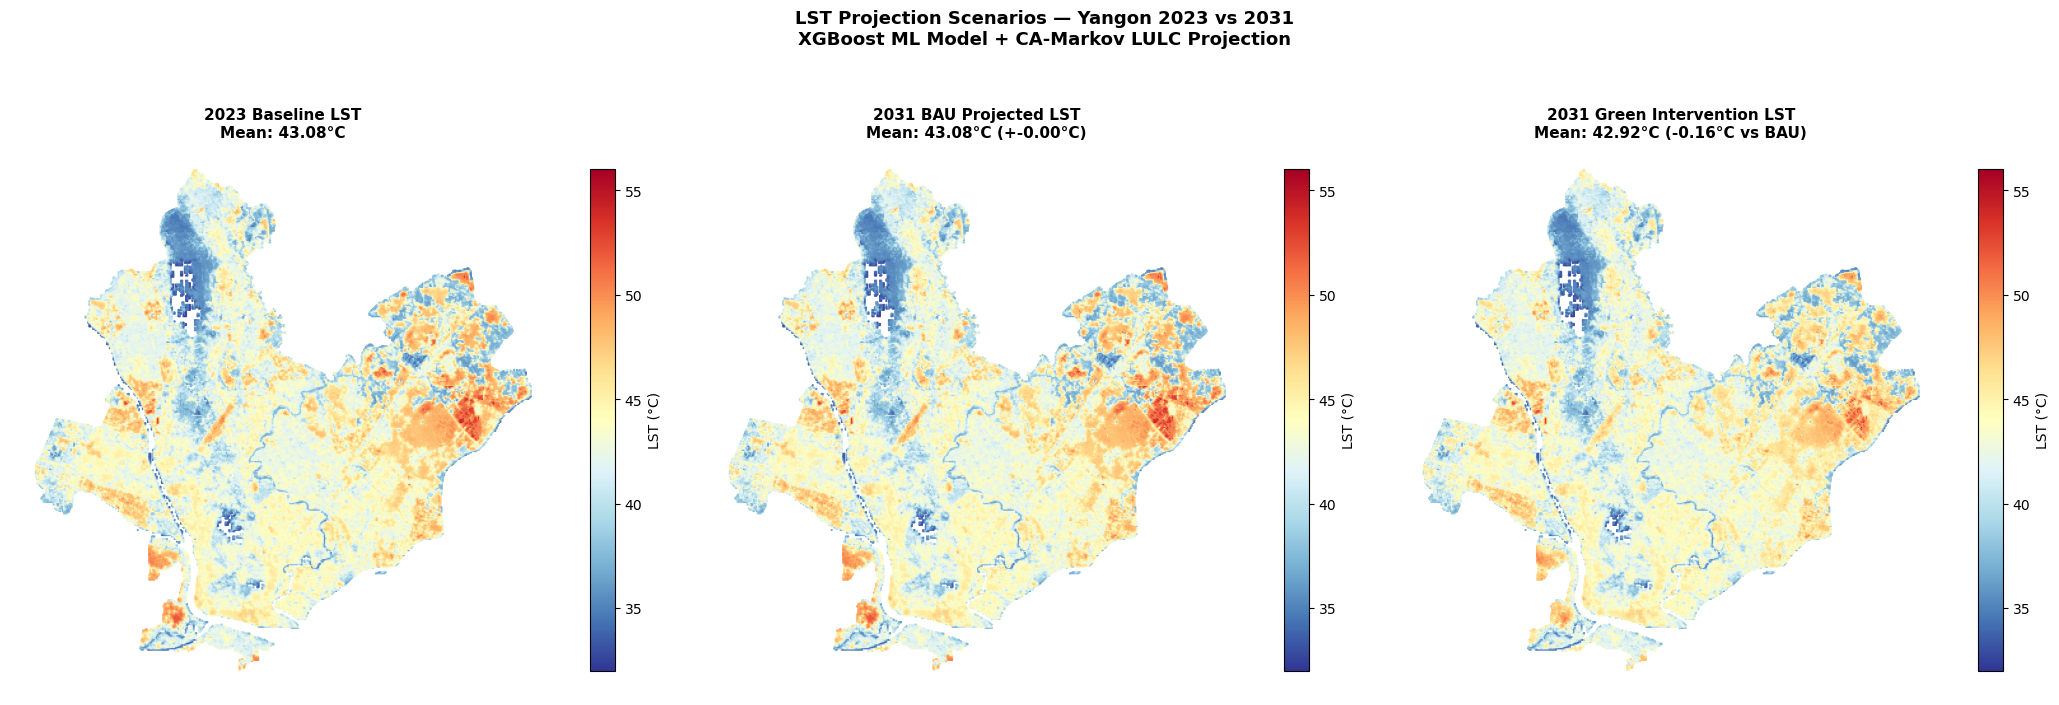

✅ Scenario map saved!


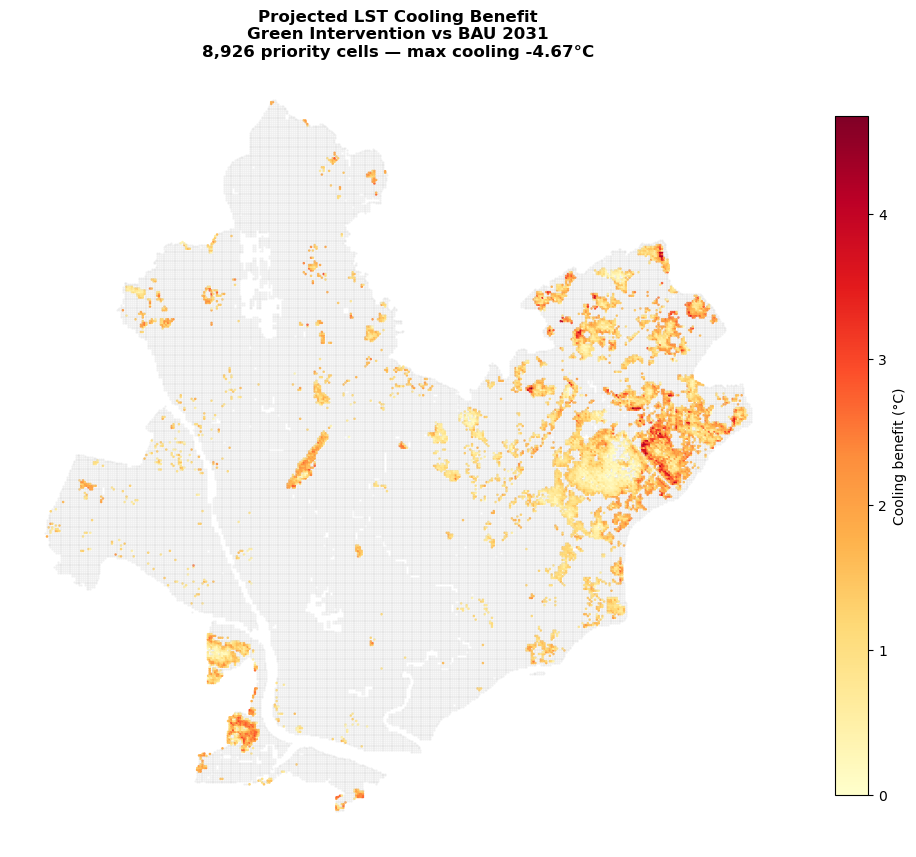

✅ Cooling benefit map saved!
✅ Results CSV saved: C:\Users\Khant Htoo Kyaw\Documents\Yangon_Thesis\data\tables\LST_projections_2031.csv

PHASE 5 COMPLETE! ✅


In [10]:
import matplotlib.pyplot as plt
import os

chart_dir = os.path.join(BASE, "outputs", "charts")
os.makedirs(chart_dir, exist_ok=True)

# Use centroids from grid (already in df_clean from Cell 5)
x_coords = df_clean['cx'].values
y_coords = df_clean['cy'].values

fig, axes = plt.subplots(1, 3, figsize=(21, 8))
vmin = 32
vmax = 56

# Map 1 — 2023 Baseline
sc1 = axes[0].scatter(x_coords, y_coords,
                      c=LST_2023_pred, cmap='RdYlBu_r',
                      s=0.3, vmin=vmin, vmax=vmax)
axes[0].set_title(f'2023 Baseline LST\nMean: {LST_2023_pred.mean():.2f}°C',
                  fontsize=11, fontweight='bold')
axes[0].set_aspect('equal')
axes[0].axis('off')
plt.colorbar(sc1, ax=axes[0], shrink=0.7, label='LST (°C)')

# Map 2 — 2031 BAU
sc2 = axes[1].scatter(x_coords, y_coords,
                      c=LST_2031_bau, cmap='RdYlBu_r',
                      s=0.3, vmin=vmin, vmax=vmax)
axes[1].set_title(f'2031 BAU Projected LST\nMean: {LST_2031_bau.mean():.2f}°C '
                  f'(+{LST_2031_bau.mean()-LST_2023_pred.mean():.2f}°C)',
                  fontsize=11, fontweight='bold')
axes[1].set_aspect('equal')
axes[1].axis('off')
plt.colorbar(sc2, ax=axes[1], shrink=0.7, label='LST (°C)')

# Map 3 — 2031 Green
sc3 = axes[2].scatter(x_coords, y_coords,
                      c=LST_2031_green, cmap='RdYlBu_r',
                      s=0.3, vmin=vmin, vmax=vmax)
axes[2].set_title(f'2031 Green Intervention LST\nMean: {LST_2031_green.mean():.2f}°C '
                  f'(-{LST_2031_bau.mean()-LST_2031_green.mean():.2f}°C vs BAU)',
                  fontsize=11, fontweight='bold')
axes[2].set_aspect('equal')
axes[2].axis('off')
plt.colorbar(sc3, ax=axes[2], shrink=0.7, label='LST (°C)')

plt.suptitle('LST Projection Scenarios — Yangon 2023 vs 2031\n'
             'XGBoost ML Model + CA-Markov LULC Projection',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(chart_dir, "LST_projection_3scenarios.png"),
            dpi=300, bbox_inches='tight')
plt.show()
print("✅ Scenario map saved!")

# Cooling benefit map
fig2, ax2 = plt.subplots(figsize=(10, 10))
benefit_mask = cooling_benefit > 0.1
sc = ax2.scatter(x_coords[benefit_mask], y_coords[benefit_mask],
                 c=cooling_benefit[benefit_mask],
                 cmap='YlOrRd', s=0.8,
                 vmin=0, vmax=cooling_benefit.max())
ax2.scatter(x_coords[~benefit_mask], y_coords[~benefit_mask],
            c='lightgrey', s=0.3, alpha=0.3)
plt.colorbar(sc, ax=ax2, shrink=0.7, label='Cooling benefit (°C)')
ax2.set_title(f'Projected LST Cooling Benefit\n'
              f'Green Intervention vs BAU 2031\n'
              f'{n_priority:,} priority cells — '
              f'max cooling -{cooling_benefit.max():.2f}°C',
              fontsize=12, fontweight='bold')
ax2.set_aspect('equal')
ax2.axis('off')
plt.tight_layout()
plt.savefig(os.path.join(chart_dir, "cooling_benefit_map.png"),
            dpi=300, bbox_inches='tight')
plt.show()
print("✅ Cooling benefit map saved!")

# Save complete results CSV
proj_path = os.path.join(BASE, "data", "tables", "LST_projections_2031.csv")
save_cols = [c for c in ['cell_id', 'cx', 'cy', 'BCR',
                          'morph_class', 'LST', 'lulc_2023',
                          'lulc_2031', 'LST_2023_pred',
                          'LST_2031_bau', 'LST_change_bau',
                          'LST_2031_green', 'cooling_benefit']
             if c in df_clean.columns]
df_clean[save_cols].to_csv(proj_path, index=False)
print(f"✅ Results CSV saved: {proj_path}")
print("\nPHASE 5 COMPLETE! ✅")